# Association Rules: Apriori and FP-Growth
**Owner:** Mohid · **Course:** DSAI 4102 · **Random seed:** 42

This notebook covers H1–H4 for MovieLens genre association rules. Run the notebook from top to bottom. `src/rules.py` contains the two functions shared with the team.

**Dataset used:** An independently prepared 5% sample of MovieLens users, retaining all their available ratings, saved locally as `data/sample_ratings.parquet` (10,047 selected users in the current analysis). It is not confirmed to be the identical cleaned 5% sample produced by Mouaz. For team integration, verify thresholds and shared function outputs on Mouaz's official cleaned files; do not upload `data/` to GitHub. If Parquet is absent, a truncated raw-data fallback is used only for a preliminary code check.

In [17]:
# Setup — run first, from the project/notebooks folder
from pathlib import Path
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

SEED = 42
rng = np.random.default_rng(SEED)
# Work whether Jupyter was launched from the project root or notebooks/.
candidates = [Path.cwd(), Path.cwd().parent]
# Optional fallback for the nested folder used by the downloaded GitHub ZIP.
candidates.append(Path.home() / "Downloads" / "movie-audience-data-mining-project-main" / "movie-audience-data-mining-project-main")
PROJECT = next((p.resolve() for p in candidates if (p / "src" / "rules.py").is_file()), None)
if PROJECT is None:
    raise FileNotFoundError("Open JupyterLab in your project folder; cannot locate src/rules.py")
sys.path.insert(0, str(PROJECT))
from src.rules import build_transactions, mine_rules

DATA = PROJECT / "data"
FIG = PROJECT / "figures"
FIG.mkdir(parents=True, exist_ok=True)
print("Project:", PROJECT)
print("Data directory:", DATA)
print("Loaded functions from:", __import__("src.rules", fromlist=["x"]).__file__)

Project: C:\Users\lolmo\Downloads\movie-audience-data-mining-project-main\movie-audience-data-mining-project-main
Data directory: C:\Users\lolmo\Downloads\movie-audience-data-mining-project-main\movie-audience-data-mining-project-main\data
Loaded functions from: C:\Users\lolmo\Downloads\movie-audience-data-mining-project-main\movie-audience-data-mining-project-main\src\rules.py


## Data source and limitations
The MovieLens raw files provide ratings and movie genres. The cleaned sample in `data/sample_ratings.parquet` has **complete histories for its selected users**; `PRELIMINARY: False` below refers only to this completeness, not to confirmation against Mouaz's officially prepared group dataset.

For full-group validation, compare against Mouaz's cleaned Parquet files. The group should retain consistent data cleaning, random seed, and rule thresholds. The raw-file fallback is partial and must not be treated as a final result.

In [18]:
# Choose the best available dataset. Do not upload raw data to GitHub.
parquet_sample = DATA / "sample_ratings.parquet"
parquet_clean = DATA / "clean_ratings.parquet"

if parquet_sample.exists():
    ratings_df = pd.read_parquet(parquet_sample)
    SOURCE = "locally prepared 5% user sample (complete user histories)"
    PRELIMINARY = False
elif parquet_clean.exists():
    ratings_df = pd.read_parquet(parquet_clean)
    SOURCE = "cleaned full ratings (complete histories)"
    PRELIMINARY = False
elif (DATA / "ratings.csv").exists() and (DATA / "movies.csv").exists():
    raw_ratings = pd.read_csv(DATA / "ratings.csv", nrows=500000)
    movie_genres = pd.read_csv(DATA / "movies.csv", usecols=["movieId", "genres"])
    ratings_df = raw_ratings.merge(movie_genres, on="movieId", how="inner", validate="many_to_one")
    SOURCE = "first 500,000 raw ratings — INCOMPLETE user histories"
    PRELIMINARY = True
else:
    raise FileNotFoundError("Place sample_ratings.parquet or clean_ratings.parquet in data/, or ratings.csv and movies.csv")

USER = "userId" if "userId" in ratings_df.columns else "user"
assert {USER, "rating", "genres"}.issubset(ratings_df.columns)
all_user_ids = np.sort(ratings_df[USER].dropna().unique())
print("Data:", SOURCE)
print("Rows:", len(ratings_df), "Users:", len(all_user_ids))
print("PRELIMINARY:", PRELIMINARY)
display(ratings_df.head(3))

Data: locally prepared 5% user sample (complete user histories)
Rows: 1599232 Users: 10047
PRELIMINARY: False


,userId,movieId,rating,timestamp,genres
0,1,17,4.0,944249077,"[Drama, Romance]"
1,1,25,1.0,944250228,"[Drama, Romance]"
2,1,29,2.0,943230976,"[Adventure, Drama, Fantasy, Mystery, Sci-Fi]"


## H1 — Genre transactions
A liked movie has a rating of **4.0 or higher**. We remove `IMAX` (screen format) and `(no genres listed)`. One user becomes one Boolean row: each genre is `True` if at least **10%** of that user's liked movies have that genre. One movie may contribute to several genre counts, but only once to the number of liked movies.

In [19]:
transactions_10 = build_transactions(ratings_df, all_user_ids, share_threshold=0.10)
transactions_20 = build_transactions(ratings_df, all_user_ids, share_threshold=0.20)
removed_users = len(all_user_ids) - len(transactions_10)

h1_summary = pd.DataFrame({
    "threshold": [0.10, 0.20],
    "retained_users": [len(transactions_10), len(transactions_20)],
    "avg_genres_per_user": [transactions_10.sum(axis=1).mean(), transactions_20.sum(axis=1).mean()],
})
print("Users with no liked movies with valid genres:", removed_users)
display(h1_summary.round(3))

popularity = pd.DataFrame({
    "10% share: users (%)": 100 * transactions_10.mean(axis=0),
    "20% share: users (%)": 100 * transactions_20.mean(axis=0),
}).sort_values("10% share: users (%)", ascending=False)
display(popularity.round(1))
display(transactions_10.head())

Users with no liked movies with valid genres: 8


,threshold,retained_users,avg_genres_per_user
0,0.1,10039,8.782
1,0.2,10039,5.381


,10% share: users (%),20% share: users (%)
genres,,
Drama,99.0,95.7
Comedy,94.4,77.7
Thriller,91.0,71.2
Action,88.0,68.1
Adventure,85.2,58.7
Crime,83.0,46.7
Romance,74.1,37.2
Sci-Fi,68.1,35.7
Fantasy,48.5,14.2


genres,Action,Adventure,Animation,Children,Comedy,Crime,Documentary,Drama,Fantasy,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
userId,,,,,,,,,,,,,,,,,,
1,True,True,False,False,True,True,False,True,False,False,False,False,False,True,True,True,True,False
80,True,True,False,False,False,True,False,True,False,False,True,False,True,False,True,True,False,False
104,True,True,False,False,True,True,False,True,False,False,False,False,True,True,True,True,False,False
113,True,False,False,False,True,True,False,True,True,False,False,False,False,True,True,True,False,False
125,True,True,False,False,True,True,False,True,False,True,False,False,True,True,True,True,True,False


**H1 interpretation.** The 20% preference threshold is stricter, so the average genre count per transaction cannot increase. The work plan recommends **10% as the default** unless it produces nearly every genre for nearly every user. Use the table above to justify that choice for the **actual dataset shown in the Data cell**. Popular genres can give high confidence without a meaningful association; that is why H3 examines **lift**.

## H2 — Apriori versus FP-Growth
Both algorithms find frequent genre itemsets, but Apriori generates candidate itemsets and FP-Growth uses an FP-tree. We check that their itemsets **and supports agree**, then time 10%, 25%, 50%, and 100% of a reproducible benchmark sample. Each time is the mean of three runs.

**Runtime control:** The benchmark uses up to 400 users so that the `0.005` experiment is practical on a student laptop. Those percentages refer to this **benchmark subset**, not necessarily all MovieLens users. To benchmark the complete sample later, change `BENCHMARK_MAX_USERS` to `None`; that may be slow or use substantial memory.

In [20]:
BENCHMARK_MAX_USERS = 400  # change to None for all users in the selected dataset
benchmark_source = transactions_10.sample(frac=1, random_state=SEED)
benchmark_data = (benchmark_source if BENCHMARK_MAX_USERS is None
                  else benchmark_source.head(BENCHMARK_MAX_USERS))
print("Benchmark users:", len(benchmark_data), "of", len(transactions_10), "available")

frequent_a = apriori(benchmark_data, min_support=0.10, use_colnames=True)
frequent_f = fpgrowth(benchmark_data, min_support=0.10, use_colnames=True)
def support_lookup(frame):
    return {tuple(sorted(items)): float(sup)
            for items, sup in zip(frame["itemsets"], frame["support"])}
lookup_a, lookup_f = support_lookup(frequent_a), support_lookup(frequent_f)
assert lookup_a.keys() == lookup_f.keys(), "Apriori and FP-Growth disagree on itemsets"
assert all(np.isclose(lookup_a[k], lookup_f[k], atol=1e-10) for k in lookup_a), "Supports differ"
print("PASS: identical itemsets and support values (", len(lookup_a), "itemsets )")

Benchmark users: 400 of 10039 available
PASS: identical itemsets and support values ( 2473 itemsets )


,support,users,algorithm,avg_seconds
0,0.100,40,Apriori,0.0384
1,0.100,40,FP-Growth,0.0216
2,0.100,100,Apriori,0.0313
3,0.100,100,FP-Growth,0.0255
4,0.100,200,Apriori,0.0379
5,0.100,200,FP-Growth,0.0388
6,0.100,400,Apriori,0.0457
7,0.100,400,FP-Growth,0.0466
8,0.005,40,Apriori,0.1752
9,0.005,40,FP-Growth,0.0614


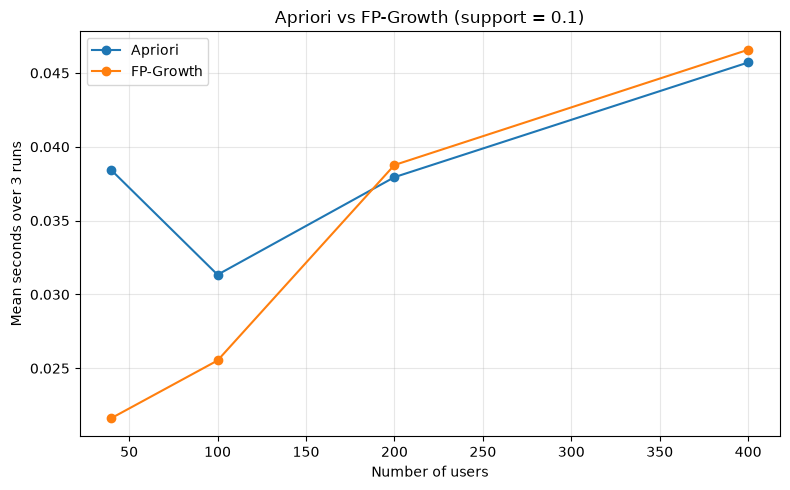

Saved: C:\Users\lolmo\Downloads\movie-audience-data-mining-project-main\movie-audience-data-mining-project-main\figures\h2_timing_support_010.png


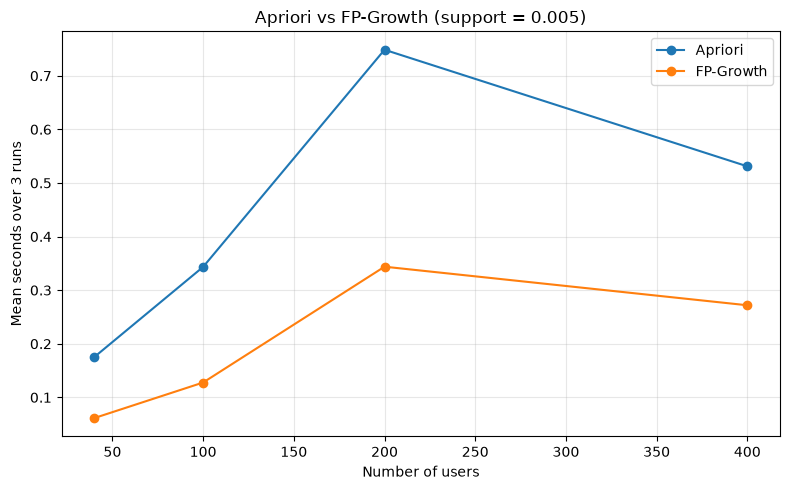

Saved: C:\Users\lolmo\Downloads\movie-audience-data-mining-project-main\movie-audience-data-mining-project-main\figures\h2_timing_support_0005.png


In [21]:
# Time both algorithms at standard and low support, 3 repeats per size.
bench_rows = []
for support in [0.10, 0.005]:
    for frac in [0.10, 0.25, 0.50, 1.00]:
        n = max(1, round(len(benchmark_data) * frac))
        sample = benchmark_data.iloc[:n]
        for name, fn in [("Apriori", apriori), ("FP-Growth", fpgrowth)]:
            elapsed = []
            for repeat in range(3):
                start = time.perf_counter()
                fn(sample, min_support=support, use_colnames=True)
                elapsed.append(time.perf_counter() - start)
            bench_rows.append({"support": support, "users": n, "algorithm": name,
                               "avg_seconds": float(np.mean(elapsed))})
bench_df = pd.DataFrame(bench_rows)
display(bench_df.round(4))

for support, name in [(0.10, "h2_timing_support_010.png"), (0.005, "h2_timing_support_0005.png")]:
    frame = bench_df.loc[bench_df["support"] == support]
    fig, ax = plt.subplots(figsize=(8, 5))
    for alg in ["Apriori", "FP-Growth"]:
        line = frame.loc[frame["algorithm"] == alg]
        ax.plot(line["users"], line["avg_seconds"], marker="o", label=alg)
    ax.set(title=f"Apriori vs FP-Growth (support = {support})",
           xlabel="Number of users", ylabel="Mean seconds over 3 runs")
    ax.legend(); ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(FIG / name, dpi=180)
    plt.show()
    print("Saved:", FIG / name)

**H2 interpretation.** Compare the timings printed above, not just the shape of the lines. In an earlier 323-user preliminary experiment at support `0.005`, FP-Growth was faster at every tested size. Apriori's candidate generation is more expensive when many itemsets are frequent. Short timings vary due to computer load, which is why each measurement is repeated three times. Your **current rerun** is the source of truth.

## H3 — Support, confidence, and lift
**Support** is the fraction of user transactions that contain both sides of the rule. **Confidence** is the fraction of users with the antecedent who also have the consequent. **Lift** compares confidence with how common the consequent is overall; lift near 1 is weak evidence of a special association.

The plan requires a 4×3 threshold grid plus two quantities in each cell: all rules and rules with lift above 1.2. These can generate many rules even with 18 genre columns, so the **grid uses at most 323 reproducibly sampled users** for a manageable exploratory run.

In [22]:
H3_GRID_MAX_USERS = 323
h3_grid_data = transactions_10.sample(frac=1, random_state=SEED).head(H3_GRID_MAX_USERS)
threshold_rows = []
for support in [0.01, 0.02, 0.05, 0.10]:
    its = fpgrowth(h3_grid_data, min_support=support, use_colnames=True)
    can_form_rules = not its.empty and its["itemsets"].map(len).ge(2).any()
    for confidence in [0.50, 0.60, 0.70]:
        if can_form_rules:
            res = association_rules(its, num_itemsets=len(h3_grid_data),
                                    metric="confidence", min_threshold=confidence)
            total = len(res)
            strong = int(res["lift"].gt(1.2).sum())
        else:
            total = strong = 0
        threshold_rows.append({"support": support, "confidence": confidence,
                               "rules": total, "lift_above_1_2": strong})
threshold_df = pd.DataFrame(threshold_rows)
threshold_grid = threshold_df.assign(
    summary=lambda f: f["rules"].astype(str) + " total / " + f["lift_above_1_2"].astype(str) + " strong"
).pivot(index="support", columns="confidence", values="summary")
display(threshold_grid)
threshold_df.to_csv(FIG / "h3_threshold_grid.csv", index=False)
print("Grid users:", len(h3_grid_data), "— saved:", FIG / "h3_threshold_grid.csv")

confidence,0.5,0.6,0.7
support,,,
0.01,522666 total / 328764 strong,379329 total / 225804 strong,266751 total / 151766 strong
0.02,298317 total / 163523 strong,218724 total / 108670 strong,153201 total / 70683 strong
0.05,134806 total / 62125 strong,101577 total / 41132 strong,70971 total / 25639 strong
0.10,67528 total / 25771 strong,50436 total / 15620 strong,34534 total / 9185 strong


Grid users: 323 — saved: C:\Users\lolmo\Downloads\movie-audience-data-mining-project-main\movie-audience-data-mining-project-main\figures\h3_threshold_grid.csv


### Selecting practical thresholds with a 1,000-user sample
The required 4 × 3 grid above uses a smaller 323-user subset to keep low-support experiments manageable. The following experiment compares stricter support and confidence combinations on **1,000 users from the same complete-history 5% sample**. The selected thresholds will also be evaluated across all available sampled users. A fixed random seed makes the 1,000-user selection reproducible.

In [23]:
H3_TARGET_USERS = 1000
h3_rng = np.random.default_rng(SEED)
h3_user_ids = h3_rng.choice(all_user_ids, size=min(H3_TARGET_USERS, len(all_user_ids)), replace=False)
h3_transactions = build_transactions(ratings_df, h3_user_ids, share_threshold=0.10)
strong_count_rows = []
for support in [0.25, 0.30, 0.35]:
    its = fpgrowth(h3_transactions, min_support=support, use_colnames=True)
    for confidence in [0.80, 0.85, 0.90]:
        if its.empty or not its["itemsets"].map(len).ge(2).any():
            count = 0
        else:
            rs = association_rules(its, num_itemsets=len(h3_transactions),
                                   metric="confidence", min_threshold=confidence)
            count = int(rs["lift"].gt(1.2).sum())
        strong_count_rows.append({"support":support, "confidence":confidence, "strong_rules":count})
threshold_choices = pd.DataFrame(strong_count_rows)
display(threshold_choices)
print("Possible settings yielding 20 to 200 strong rules:")
display(threshold_choices[threshold_choices["strong_rules"].between(20,200)])

,support,confidence,strong_rules
0,0.25,0.80,113
1,0.25,0.85,47
2,0.25,0.90,28
3,0.30,0.80,22
4,0.30,0.85,6
5,0.30,0.90,2
6,0.35,0.80,0
7,0.35,0.85,0
8,0.35,0.90,0


Possible settings yielding 20 to 200 strong rules:


,support,confidence,strong_rules
0,0.25,0.80,113
1,0.25,0.85,47
2,0.25,0.90,28
3,0.30,0.80,22


In [24]:
# A transparent provisional choice; change only if the cleaned-data results justify it.
FINAL_SUPPORT = 0.25
FINAL_CONFIDENCE = 0.85
selected_rules = mine_rules(ratings_df, h3_user_ids, FINAL_SUPPORT, FINAL_CONFIDENCE)
strong_rules = selected_rules.loc[selected_rules["lift"] > 1.2].copy()
top_15 = strong_rules.sort_values("lift", ascending=False).head(15)
print("Source:", SOURCE)
print("Users selected:", len(h3_user_ids), " / transactions:", len(h3_transactions))
print("Support:", FINAL_SUPPORT, "Confidence:", FINAL_CONFIDENCE)
print("All rules:", len(selected_rules), "; rules with lift > 1.2:", len(strong_rules))
if not 20 <= len(strong_rules) <= 200:
    print("NOTE: strong-rule count is outside the work-plan target; reconsider the settings using the table above.")
display(top_15.round(3))
top_15.to_csv(FIG / "h3_top15_rules.csv", index=False)

Source: locally prepared 5% user sample (complete user histories)
Users selected: 1000  / transactions: 999
Support: 0.25 Confidence: 0.85
All rules: 3087 ; rules with lift > 1.2: 47


,antecedents,consequents,support,confidence,lift
0,"Comedy, Crime, Fantasy, Sci-Fi","Action, Adventure, Drama, Thriller",0.259,0.952,1.248
1,"Crime, Fantasy, Sci-Fi","Action, Adventure, Drama, Thriller",0.275,0.945,1.239
2,"Crime, Fantasy, Sci-Fi","Action, Adventure, Comedy, Drama, Thriller",0.259,0.890,1.237
3,"Comedy, Crime, Fantasy, Sci-Fi","Action, Adventure, Thriller",0.260,0.956,1.235
4,"Comedy, Crime, Drama, Fantasy, Sci-Fi","Action, Adventure, Thriller",0.259,0.956,1.235
5,"Crime, Drama, Fantasy, Sci-Fi","Action, Adventure, Thriller",0.275,0.952,1.230
6,"Comedy, Crime, Fantasy, Sci-Fi, Thriller","Action, Adventure, Drama",0.259,0.981,1.230
7,"Crime, Drama, Fantasy, Sci-Fi","Action, Adventure, Comedy, Thriller",0.259,0.896,1.228
8,"Adventure, Drama, Mystery","Action, Crime, Thriller",0.274,0.881,1.228
9,"Crime, Fantasy, Sci-Fi","Action, Adventure, Thriller",0.276,0.948,1.226


In [25]:
# Find 2–3 examples where confidence is high but lift is near 1.
# Use the broader 0.10 support / 0.70 confidence rule collection for illustrative checks.
near_itemsets = fpgrowth(h3_grid_data, min_support=0.10, use_colnames=True)
if near_itemsets.empty or not near_itemsets["itemsets"].map(len).ge(2).any():
    near = pd.DataFrame(columns=["antecedents", "consequents", "support", "confidence", "lift"])
else:
    near_all = association_rules(near_itemsets, num_itemsets=len(h3_grid_data),
                                 metric="confidence", min_threshold=0.70)
    near = near_all.loc[
        near_all["consequents"].map(len).eq(1) &
        near_all["lift"].between(0.95, 1.05)
    ].copy()
near["distance_from_one"] = (near["lift"] - 1).abs()
near = near.sort_values(["distance_from_one", "confidence"], ascending=[True, False]).head(3)
near["consequent_popularity"] = near["consequents"].map(
    lambda itemset: float(h3_grid_data[next(iter(itemset))].mean()))
for col in ["antecedents", "consequents"]:
    near[col] = near[col].map(lambda s: ", ".join(sorted(s)))
if near.empty:
    print("No rules matching confidence >= .70 and lift between .95 and 1.05 in this sample.")
else:
    display(near[["antecedents","consequents","support","confidence","consequent_popularity","lift"]].round(3))

,antecedents,consequents,support,confidence,consequent_popularity,lift
1726,"Action, Adventure, Comedy, Romance, Thriller",Drama,0.498,0.994,0.994,1.0
6,"Drama, Thriller",Comedy,0.848,0.929,0.929,1.0
208,"Crime, Drama, Thriller",Comedy,0.728,0.929,0.929,1.0


**H3 interpretation.** High confidence is not necessarily strong evidence of association: when the consequent is already popular, confidence can be high while lift stays around 1. The low-lift examples demonstrate this. The top-15 table ranks **associations, not causes**. Several rules overlap heavily because common movie genres co-occur.

**Chosen thresholds for the locally prepared sample:** `min_support=0.25`, `min_confidence=0.85`, with lift above `1.2` used for the strong-rule filter. The final cells verify how many rules remain across the whole 5% sample. The team should check these thresholds against its official cleaned files.

## H4 — Shared functions and edge-case testing
The team calls `mine_rules(ratings_df, user_ids, min_support, min_confidence)` for whole-audience and cluster-specific rules. It returns the five agreed columns, genre names as sorted comma-separated text, and an empty table with those same columns if no rules meet the thresholds.

In [26]:
# Small deterministic example: 2 users with likes, 1 without.
test_ratings = pd.DataFrame({
    "user": [1,1,1,2,2,3], "rating": [5,4.5,2,4,3,2.5],
    "genres": [
        ["Action", "Sci-Fi"], ["Action", "Adventure"], ["Comedy"],
        ["Drama"], ["Romance"], ["Comedy"]
    ]
})
small_tx = build_transactions(test_ratings, [1,2,3])
assert list(small_tx.index) == [1,2]
small_rules = mine_rules(test_ratings, [1,2,3], min_support=0.25, min_confidence=0.50)
assert list(small_rules.columns) == ["antecedents","consequents","support","confidence","lift"]
assert len(small_rules) == 12, f"Expected 12 directional rules; got {len(small_rules)}"
print("Small test PASS: 12 rules with expected schema")

no_likes = test_ratings.copy(); no_likes["rating"] = 1.0
empty_rules = mine_rules(no_likes, [1,2,3], min_support=.25, min_confidence=.50)
assert empty_rules.empty and list(empty_rules.columns) == list(small_rules.columns)
print("No-rules test PASS: empty table with five columns")

Small test PASS: 12 rules with expected schema
No-rules test PASS: empty table with five columns


In [27]:
# Required group sizes: 10 users, random 1,000 (if available), and all available.
functional_tests = []
h4_rng = np.random.default_rng(SEED)
for label, chosen_ids in [
    ("10 users", all_user_ids[:10]),
    ("random 1,000 users", h4_rng.choice(all_user_ids, min(1000, len(all_user_ids)), replace=False)),
    ("all users in selected dataset", all_user_ids),
]:
    found = mine_rules(ratings_df, chosen_ids, FINAL_SUPPORT, FINAL_CONFIDENCE)
    assert list(found.columns) == ["antecedents","consequents","support","confidence","lift"]
    functional_tests.append({"test": label, "users_requested":len(chosen_ids), "rules_found":len(found)})
display(pd.DataFrame(functional_tests))
if len(all_user_ids) < 1000:
    print("NOTE: 1,000-user test unavailable in this input; run again on the cleaned dataset containing >= 1,000 users.")

C:\Users\lolmo\anaconda3\Lib\site-packages\mlxtend\frequent_patterns\association_rules.py:184: RuntimeWarning: invalid value encountered in divide
  cert_metric = np.where(certainty_denom == 0, 0, certainty_num / certainty_denom)


,test,users_requested,rules_found
0,10 users,10,23833
1,"random 1,000 users",1000,3087
2,all users in selected dataset,10047,3090


In [28]:

# Final H3 verification on all available users

strong_all = found[found["lift"] > 1.2].copy()

print("Support:", FINAL_SUPPORT)
print("Confidence:", FINAL_CONFIDENCE)
print("Total rules:", len(found))
print("Strong rules:", len(strong_all))
print("Target of 20-200 met:", 20 <= len(strong_all) <= 200)

print("\nTop 15 strong rules:")
display(strong_all.sort_values("lift", ascending=False).head(15))

print("\nNon-finite metric values:",
      (~np.isfinite(found[["support", "confidence", "lift"]].to_numpy())).sum())


Support: 0.25
Confidence: 0.85
Total rules: 3090
Strong rules: 100
Target of 20-200 met: True

Top 15 strong rules:


,antecedents,consequents,support,confidence,lift
0,"Crime, Fantasy, Sci-Fi","Action, Adventure, Comedy, Drama, Thriller",0.272139,0.887878,1.258600
1,"Crime, Drama, Fantasy, Sci-Fi","Action, Adventure, Comedy, Thriller",0.272139,0.893102,1.255019
2,"Crime, Fantasy, Sci-Fi","Action, Adventure, Comedy, Thriller",0.273732,0.893078,1.254984
3,"Comedy, Crime, Fantasy, Sci-Fi","Action, Adventure, Drama, Thriller",0.272139,0.937221,1.253332
4,"Crime, Fantasy, Sci-Fi","Action, Adventure, Drama, Thriller",0.287180,0.936952,1.252971
5,"Action, Adventure, Crime, Fantasy, Thriller",Sci-Fi,0.288774,0.852396,1.251786
6,"Action, Adventure, Crime, Drama, Fantasy, Thri...",Sci-Fi,0.287180,0.852202,1.251501
7,"Action, Adventure, Fantasy, Thriller",Sci-Fi,0.340771,0.851631,1.250661
8,"Action, Adventure, Drama, Fantasy, Thriller",Sci-Fi,0.336687,0.851171,1.249986
9,"Comedy, Crime, Drama, Fantasy, Sci-Fi","Action, Adventure, Thriller",0.272139,0.942719,1.249367



Non-finite metric values: 0


### H3 conclusion and team handoff
Support `0.25`, confidence `0.85`, and a lift filter above `1.2` provide a manageable collection of association rules in the **locally prepared complete-history 5% user sample**. The numerical counts are calculated in the code below so they always match the latest run. These are not results from all 32 million MovieLens ratings or from Mouaz's separately prepared official cleaned sample.

In [29]:
# Summary generated from the current run — no hard-coded rule counts.
h3_1000_rules = int((selected_rules["lift"] > 1.2).sum())
h3_all_rules = int((found["lift"] > 1.2).sum())
print("Selected support:", FINAL_SUPPORT, "confidence:", FINAL_CONFIDENCE)
print("Strong rules in 1,000-user experiment:", h3_1000_rules)
print("Strong rules across all selected users:", h3_all_rules)
print("Target of 20–200 met (1,000 users):", 20 <= h3_1000_rules <= 200)
print("Target of 20–200 met (entire 5% sample):", 20 <= h3_all_rules <= 200)
print("Data source:", SOURCE)
print("NOTE: Independently prepared 5% sample; verify against the group's official cleaned dataset.")


Selected support: 0.25 confidence: 0.85
Strong rules in 1,000-user experiment: 47
Strong rules across all selected users: 100
Target of 20–200 met (1,000 users): True
Target of 20–200 met (entire 5% sample): True
Data source: locally prepared 5% user sample (complete user histories)
NOTE: Independently prepared 5% sample; verify against the group's official cleaned dataset.
